# 01 — The recorded dataset, and the constant-velocity baseline (2026-10-26)

Read-only: this notebook only **reads** `dataset_codes/runs/*/samples/*.npz`. Nothing in the pipeline changes.

1. **Load** every run and see what a sample contains (every field, shape, unit, frame).
2. **Look** at samples: in the pedestrian's own frame (what the network gets) and in the odom/world frame (what the robot and the MPC use), and step through consecutive samples frame by frame.
3. **CVM baseline**: predict the future by walking on with the last velocity, and measure the error per run (ADE / FDE), per prediction step, and how often the prediction runs into an occupied cell.

CVM has nothing to train. It is the reference every learned model is compared with.

**Run it** (once, in a terminal, outside ROS — it does not need ROS):
```bash
python3 -m venv ~/venvs/thesis && source ~/venvs/thesis/bin/activate
pip install numpy matplotlib jupyter ipywidgets
cd ~/ros2_ws/src/my_robot_description/notebooks && jupyter notebook
```

## What one sample is — and in which frame

A sample = **one moment T** (the *anchor*) of one pedestrian. Everything the network sees and predicts is in the
**pedestrian's own frame at T**: origin = where the pedestrian is at T, **+x = the direction it walks at T**, +y = its left.
Nothing is in the robot frame. That makes the data the same wherever in the room it happened and whichever way the
pedestrian walked (translation and rotation invariant).

| field | shape | frame / unit | meaning |
|---|---|---|---|
| `trajectory_history` | (8, 3) | pedestrian frame at T; m, m, rad | x, y, heading of the pedestrian at T−3.5 s … T (0.5 s apart, oldest first). Last row = (0, 0, 0) by construction |
| `future_target` | (12, 3) | same frame | where it really is at T+0.5 … T+6.0 s — **the label** (ground truth from the simulator) |
| `crop` | (80, 80) int8 | same frame; 0.1 m cells | the robot's occupancy grid around the pedestrian: −1 unknown (not seen), 0 free, 100 occupied. Row = y (−4…4 m), column = x (−2…6 m): 2 m behind, 6 m ahead, 4 m each side. The pedestrian itself is removed |
| `ped_anchor_odom` | (3,) | **odom** frame; m, m, rad | pedestrian x, y, heading at T — the pose that defines the pedestrian frame |
| `robot_pose_odom` | (3,) | odom frame | robot x, y, heading at the grid's time (≈ T) — the camera's viewpoint for this crop |
| `history_times`, `future_times` | (8,), (12,) | simulation s | the time of every row |
| `anchor_time_sim`, `grid_stamp_sim` | scalars | simulation s | T, and the stamp of the depth data the crop came from |
| `ped_seen_anchor`, `ped_seen_history`, `ped_seen_future` | 1 / (8,) / (12,) int8 | — | could the robot see the pedestrian then? 1 yes, 0 no, −1 no grid near that time (from 2026-10-24) |
| `gated` | bool | — | the start gate was running and the whole window was open (from 2026-10-24) |
| `max_pose_gap_sec`, `lookup_offset_sec`, `sample_period_sec`, `schema`, `agent_id`, `wall_time` | | | bookkeeping |

**odom frame** = a fixed world frame whose origin is the robot's spawn pose (since 2026-10-14 the robot's odom pose is
Gazebo's true pose, so odom never drifts). The robot moves *in* it.

**"The robot's position relative to the pedestrian"** (from the last discussion) = `robot_pose_odom` expressed in the
pedestrian frame. Today it exists only at T (computed below); the network does **not** get it. Storing it for every
history step is the proposed recorder addition.

**For the MPC**: the network predicts `future_target`-like rows in the pedestrian frame; one rigid transform with
`ped_anchor_odom` puts them into odom, where the MPC plans (function `local_to_odom` below). Distances (ADE/FDE) are
the same in both frames.

In [1]:
import glob, json, math, os
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm

RUNS_DIR = Path('../dataset_codes/runs')        # notebook lives in my_robot_description/notebooks/
CROP_BEHIND, CROP_FORWARD, CROP_SIDE, RES = 2.0, 6.0, 4.0, 0.1
UNKNOWN, FREE, OCC = -1, 0, 100
USABLE_MIN_HISTORY_SEEN = 6        # proposed training filter: seen at T and in >= 6 of 8 history steps
print('runs folder:', RUNS_DIR.resolve(), '| exists:', RUNS_DIR.exists())

runs folder: /home/ali/ros2_ws/src/my_robot_description/dataset_codes/runs | exists: True


## 1. Load

In [2]:
def crop_seen(crop, r=0.25):
    # same rule as analyze_ped_visibility.py: cells within 0.25 m of the anchor mostly known
    xs = -CROP_BEHIND + (np.arange(crop.shape[1]) + 0.5) * RES
    ys = -CROP_SIDE + (np.arange(crop.shape[0]) + 0.5) * RES
    X, Y = np.meshgrid(xs, ys)
    return (crop[np.hypot(X, Y) <= r] != UNKNOWN).mean() >= 0.5

def load_sample(path):
    with np.load(path, allow_pickle=True) as d:
        s = {k: d[k] for k in d.files}
    s['file'] = path.name
    s['seen_anchor'] = bool(s['ped_seen_anchor']) if 'ped_seen_anchor' in s else crop_seen(s['crop'])
    if 'ped_seen_history' in s:
        n_seen = int((s['ped_seen_history'] == 1).sum())
        s['usable'] = bool(s['seen_anchor'] and n_seen >= USABLE_MIN_HISTORY_SEEN)
    else:
        s['usable'] = None                       # older run: history visibility was not recorded
    return s

def load_run(run_dir):
    files = sorted(Path(run_dir, 'samples').glob('*.npz'))
    samples = [load_sample(f) for f in files]
    samples.sort(key=lambda s: float(s.get('anchor_time_sim', 0.0)))
    return samples

runs = {}
for d in sorted(RUNS_DIR.glob('*')):
    if (d / 'samples').is_dir():
        sm = load_run(d)
        if sm:
            runs[d.name] = sm
print(f'{len(runs)} runs, {sum(len(v) for v in runs.values())} samples\n')
print(f'{"run":42s} {"samples":>7s} {"seen@T":>7s} {"usable":>7s}  obstacles')
for name, sm in runs.items():
    seen = np.mean([s['seen_anchor'] for s in sm])
    us = [s['usable'] for s in sm if s['usable'] is not None]
    obs = (RUNS_DIR / name / 'obstacles.yaml')
    n_obs = obs.read_text().count('- name:') if obs.exists() else 0
    print(f'{name:42s} {len(sm):7d} {seen:7.0%} {(format(np.mean(us), "7.0%") if us else "      -")}  {n_obs}')

42 runs, 3938 samples

run                                        samples  seen@T  usable  obstacles
20261005_151520                                162    100%       -  0
20261005_183917_distorted                       32    100%       -  0
20261005_190321_straigh_10hz                   119    100%       -  0
20261005_190716_straigh_10hz_faster             45    100%       -  0
20261006_170339_box                             53     66%       -  0
20261006_181321_GZ_Box                          44     64%       -  3
20261006_185149_two_boxes_scene                 90     54%       -  2
20261012_133516_T01_cross_mid                   92    100%       -  0
20261012_144349_T02_cross_near                  88    100%       -  0
20261012_144826_T03_cross_far                  105    100%       -  0
20261012_145326_T04_radial                      90    100%       -  0
20261012_145734_T05_slow                        81    100%       -  0
20261012_150130_T06_fast                        83    100% 

## 2. One sample, field by field

In [4]:
RUN = list(runs)[-1]          # <- pick any run name from the table above
IDX = 0                       # <- and a sample index
s = runs[RUN][IDX]
print(RUN, '/', s['file'], '\n')
for k, v in s.items():
    a = np.asarray(v)
    if a.ndim == 0:
        print(f'{k:22s} {str(a.dtype):8s} {a.item()}')
    else:
        print(f'{k:22s} {str(a.dtype):8s} shape {a.shape}')
print('\ntrajectory_history (x, y, heading) -- last row is the anchor:\n', np.round(s['trajectory_history'], 2))
print('\nfuture_target (x, y, heading):\n', np.round(s['future_target'], 2))
print('\ncrop values:', {int(v): int(c) for v, c in zip(*np.unique(s['crop'], return_counts=True))})

20261024_175923_G2_gate / sample_20261024_175924_000000.npz 

trajectory_history     float32  shape (8, 3)
crop                   int8     shape (80, 80)
future_target          float32  shape (12, 3)
agent_id               <U6      agent1
sample_period_sec      float64  0.5
wall_time              float64  1792852200.9090147
schema                 <U15     time_aligned_v2
anchor_time_sim        float64  18.894000000000002
grid_stamp_sim         float64  18.844
lookup_offset_sec      float64  0.05
history_times          float64  shape (8,)
future_times           float64  shape (12,)
robot_pose_odom        float64  shape (3,)
ped_anchor_odom        float64  shape (3,)
max_pose_gap_sec       float64  0.03400000000000247
ped_seen_anchor        int8     1
ped_seen_history       int8     shape (8,)
ped_seen_future        int8     shape (12,)
gated                  bool     True
file                   <U33     sample_20261024_175924_000000.npz
seen_anchor            bool     True
usable       

## 3. Look at it: pedestrian frame (network input) and odom frame (robot / MPC)

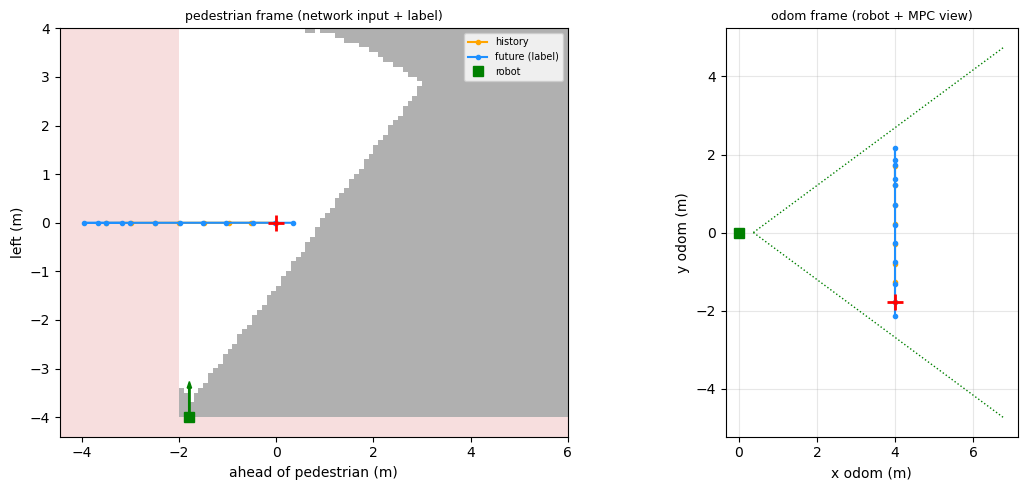

In [5]:
CMAP = ListedColormap(['#b0b0b0', '#ffffff', '#1a1a1a'])
NORM = BoundaryNorm([-1.5, -0.5, 50, 101], CMAP.N)

def local_to_odom(xy, anchor):
    # pedestrian frame -> odom: rotate by the anchor heading, shift by the anchor position
    ax, ay, ayaw = anchor
    c, s_ = math.cos(ayaw), math.sin(ayaw)
    xy = np.asarray(xy)[..., :2]
    return np.stack([ax + c * xy[..., 0] - s_ * xy[..., 1], ay + s_ * xy[..., 0] + c * xy[..., 1]], -1)

def odom_to_local(xy, anchor):
    ax, ay, ayaw = anchor
    c, s_ = math.cos(ayaw), math.sin(ayaw)
    dx, dy = np.asarray(xy)[..., 0] - ax, np.asarray(xy)[..., 1] - ay
    return np.stack([c * dx + s_ * dy, -s_ * dx + c * dy], -1)

def robot_in_ped_frame(s):
    r = s['robot_pose_odom']
    p = odom_to_local(r[:2], s['ped_anchor_odom'])
    return p, (r[2] - s['ped_anchor_odom'][2])

def plot_local(s, ax, pred=None, title=''):
    ax.set_facecolor('#f7dede')
    ax.imshow(np.where(s['crop'] == OCC, 100, s['crop']), cmap=CMAP, norm=NORM, origin='lower',
              extent=[-CROP_BEHIND, CROP_FORWARD, -CROP_SIDE, CROP_SIDE])
    h, f = s['trajectory_history'], s['future_target']
    ax.plot(h[:, 0], h[:, 1], 'o-', c='orange', ms=3, label='history')
    ax.plot(f[:, 0], f[:, 1], 'o-', c='dodgerblue', ms=3, label='future (label)')
    if pred is not None:
        ax.plot(pred[:, 0], pred[:, 1], 'x--', c='red', ms=4, label='CVM')
    (rx, ry), ryaw = robot_in_ped_frame(s)
    if abs(rx) < 12 and abs(ry) < 12:
        ax.plot(rx, ry, 's', c='green', ms=7, label='robot')
        ax.arrow(rx, ry, 0.6 * math.cos(ryaw), 0.6 * math.sin(ryaw), color='green', width=0.03)
    ax.plot(0, 0, 'r+', ms=12, mew=2)
    ax.set_title(title or ('SEEN' if s['seen_anchor'] else 'NOT SEEN'), fontsize=9)
    ax.set_xlabel('ahead of pedestrian (m)'); ax.set_ylabel('left (m)'); ax.set_aspect('equal')

def plot_odom(s, ax, pred=None):
    a = s['ped_anchor_odom']
    h, f = local_to_odom(s['trajectory_history'], a), local_to_odom(s['future_target'], a)
    ax.plot(h[:, 0], h[:, 1], 'o-', c='orange', ms=3)
    ax.plot(f[:, 0], f[:, 1], 'o-', c='dodgerblue', ms=3)
    if pred is not None:
        p = local_to_odom(pred, a); ax.plot(p[:, 0], p[:, 1], 'x--', c='red', ms=4)
    r = s['robot_pose_odom']
    ax.plot(r[0], r[1], 's', c='green', ms=7)
    for sgn in (-1, 1):                       # the camera's 73 deg view, 8 m (camera 0.37 m ahead of the robot)
        cx, cy = r[0] + 0.37 * math.cos(r[2]), r[1] + 0.37 * math.sin(r[2])
        ang = r[2] + sgn * math.radians(36.5)
        ax.plot([cx, cx + 8 * math.cos(ang)], [cy, cy + 8 * math.sin(ang)], ':', c='green', lw=1)
    ax.plot(a[0], a[1], 'r+', ms=12, mew=2)
    ax.set_title('odom frame (robot + MPC view)', fontsize=9)
    ax.set_xlabel('x odom (m)'); ax.set_ylabel('y odom (m)'); ax.set_aspect('equal'); ax.grid(alpha=0.3)

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
plot_local(s, axs[0], title='pedestrian frame (network input + label)')
plot_odom(s, axs[1])
axs[0].legend(fontsize=7, loc='upper right'); plt.tight_layout(); plt.show()

### Frame by frame through one run (needs `ipywidgets`; otherwise shows 6 consecutive samples)

In [6]:
RUN_FBF = RUN
sm = runs[RUN_FBF]

def show(i):
    s = sm[i]
    fig, axs = plt.subplots(1, 2, figsize=(12, 5))
    t = float(s.get('anchor_time_sim', np.nan))
    plot_local(s, axs[0], title=f'{i}/{len(sm)-1}  T={t:.2f} s  {"SEEN" if s["seen_anchor"] else "NOT SEEN"}'
               + ('' if s['usable'] is None else ('  usable' if s['usable'] else '  not usable')))
    plot_odom(s, axs[1]); plt.tight_layout(); plt.show()

try:
    import ipywidgets as w
    w.interact(show, i=w.IntSlider(min=0, max=len(sm) - 1, step=1, value=0, continuous_update=False))
except ImportError:
    for i in range(min(6, len(sm))):
        show(i)

interactive(children=(IntSlider(value=0, continuous_update=False, description='i', max=60), Output()), _dom_cl…

## 4. Constant-velocity model (CVM)

The pedestrian keeps the velocity of its **last history step** (the last 0.5 s): `v = (h[-1] − h[-2]) / 0.5`, and
`prediction_k = h[-1] + v · 0.5 · k` for k = 1…12. In the pedestrian frame `h[-1]` is (0, 0), so this is just
`k · (−h[-2])`.

- **ADE**: mean distance between prediction and truth over the 12 steps (6 s). **FDE**: the distance at the last step.
- **into occupied**: share of predicted points (inside the crop) that land on an occupied cell. The truth should be ~0%
  (the pedestrian does not walk through boxes); CVM goes straight, so near obstacles it will not be 0.

CVM failing is not the goal (as discussed); these numbers are the reference line and help read the data.

In [7]:
def cvm(h, n=12, dt=0.5):
    v = (h[-1, :2] - h[-2, :2]) / dt
    return np.array([h[-1, :2] + v * dt * (k + 1) for k in range(n)])

def occupied_share(crop, pts):
    c = np.floor((pts[:, 0] + CROP_BEHIND) / RES).astype(int)
    r = np.floor((pts[:, 1] + CROP_SIDE) / RES).astype(int)
    inside = (c >= 0) & (c < crop.shape[1]) & (r >= 0) & (r < crop.shape[0])
    if not inside.any():
        return np.nan
    return float((crop[r[inside], c[inside]] == OCC).mean())

def evaluate(samples, filt='usable'):
    rows = []
    for s in samples:
        if filt == 'usable' and s['usable'] is False:
            continue
        if filt in ('usable', 'seen') and not s['seen_anchor']:
            continue
        gt = s['future_target'][:, :2]
        p = cvm(s['trajectory_history'])
        err = np.linalg.norm(p - gt, axis=1)
        speed = np.linalg.norm(s['trajectory_history'][-1, :2] - s['trajectory_history'][-2, :2]) / 0.5
        rows.append({'err': err, 'speed': speed, 'occ_cvm': occupied_share(s['crop'], p),
                     'occ_gt': occupied_share(s['crop'], gt), 's': s, 'pred': p})
    return rows

FILTER = 'usable'      # 'all', 'seen' (pedestrian seen at T) or 'usable' (seen at T and >= 6/8 history steps; older runs: seen at T)
print(f'filter: {FILTER}\n')
print(f'{"run":42s} {"n":>5s} {"ADE":>6s} {"FDE":>6s} {"speed":>6s} {"CVM->occ":>9s} {"truth->occ":>10s}')
results = {}
for name, sm in runs.items():
    r = evaluate(sm, FILTER)
    if not r:
        continue
    results[name] = r
    E = np.array([x['err'] for x in r])
    print(f'{name:42s} {len(r):5d} {E.mean():6.2f} {E[:, -1].mean():6.2f} {np.mean([x["speed"] for x in r]):6.2f} '
          f'{np.nanmean([x["occ_cvm"] for x in r]):9.1%} {np.nanmean([x["occ_gt"] for x in r]):10.1%}')

filter: usable

run                                            n    ADE    FDE  speed  CVM->occ truth->occ
20261005_151520                              162   2.77   4.97   0.79      0.0%       0.0%
20261005_183917_distorted                     32   1.58   3.67   0.77      0.3%       0.0%
20261005_190321_straigh_10hz                 119   2.59   6.46   0.94      0.0%       0.0%
20261005_190716_straigh_10hz_faster           45   6.06  10.67   1.64      0.0%       0.2%
20261006_170339_box                           35   3.11   5.79   0.85      0.0%       0.0%
20261006_181321_GZ_Box                        28   2.69   5.66   0.90      1.5%       0.0%
20261006_185149_two_boxes_scene               49   1.94   4.83   0.92      0.0%       0.0%
20261012_133516_T01_cross_mid                 92   3.13   7.01   0.93      0.0%       0.0%
20261012_144349_T02_cross_near                88   2.83   5.30   0.80      0.0%       0.0%
20261012_144826_T03_cross_far                105   2.68   6.65   0.95     

### Error per prediction step (how fast CVM gets worse)

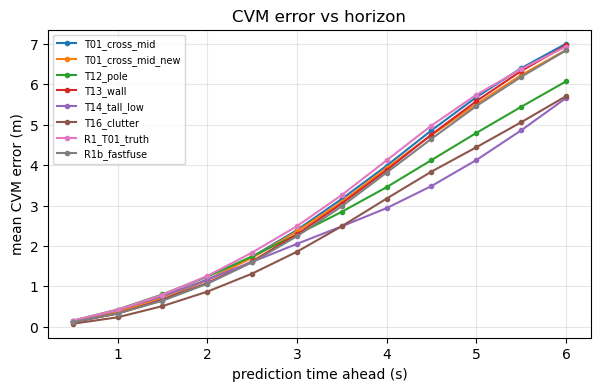

In [8]:
PICK = [n for n in results if any(k in n for k in ('T01', 'T12', 'T13', 'T14', 'T16', 'R1b'))] or list(results)[:5]
plt.figure(figsize=(7, 4))
for n in PICK:
    E = np.array([x['err'] for x in results[n]])
    plt.plot(np.arange(1, 13) * 0.5, E.mean(0), 'o-', ms=3, label=n.split('_', 2)[-1])
plt.xlabel('prediction time ahead (s)'); plt.ylabel('mean CVM error (m)'); plt.grid(alpha=0.3)
plt.legend(fontsize=7); plt.title('CVM error vs horizon'); plt.show()

### Where CVM is worst (the samples a scene-aware model should do better on)

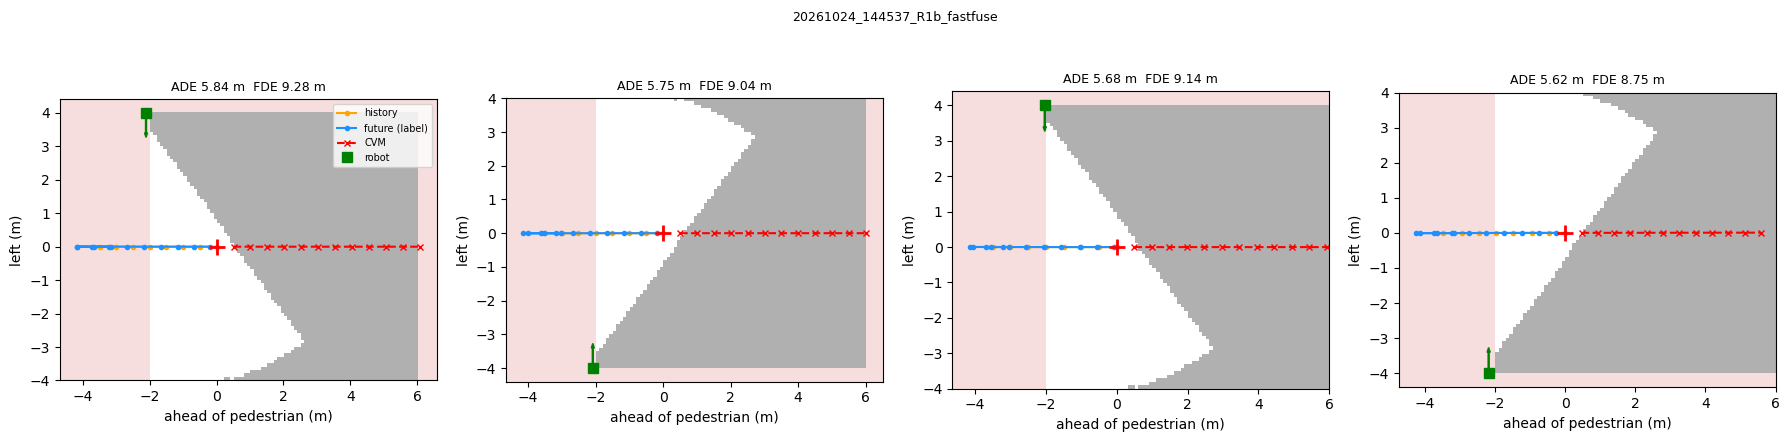

In [9]:
RUN_W = PICK[-1] if PICK else list(results)[0]      # <- an obstacle run, e.g. T12_pole / T16_clutter
worst = sorted(results[RUN_W], key=lambda x: -x['err'].mean())[:4]
fig, axs = plt.subplots(1, len(worst), figsize=(4.5 * len(worst), 4.5))
for ax, x in zip(np.atleast_1d(axs), worst):
    plot_local(x['s'], ax, pred=x['pred'], title=f'ADE {x["err"].mean():.2f} m  FDE {x["err"][-1]:.2f} m')
np.atleast_1d(axs)[0].legend(fontsize=7, loc='upper right'); plt.suptitle(RUN_W, fontsize=9); plt.tight_layout(); plt.show()

## Reading the results

- On the **open-floor** runs CVM is mostly good, except where the pedestrian reaches a goal and turns back (an
  invisible goal: unlearnable for any model — that is why real episodes will be single trips).
- On the **obstacle** runs, look at *CVM→occ*: how often going straight would walk into something the robot can see.
  That, and the worst-case plots, is where a crop-aware model has something to learn.
- The test runs were built to check the pipeline, not as training data: they include the U-turns, older recorder
  versions (no visibility flags, wheel odometry before 2026-10-14), and repeated goals.

Next (not in this notebook yet): a tiny PyTorch `Dataset` on the same loader, an overfit test on ~100 samples, then
history-only vs history+crop.